# E6: SVM × KNN × Regressão Logística (e o efeito da escala)

**Inteligência Artificial II · Arena de Personagens**

O roteiro do projeto pede comparar o SVM com **KNN** e **regressão logística**, e lista **escala** entre os desafios.
Este notebook faz essa comparação com o **mesmo protocolo** do notebook 02.

- **Hipótese (registrada em 10/11/2026, antes da execução completa):** o SVM RBF supera o KNN e a Regressão Logística,
  mas por pouco, porque o ganho principal veio das variáveis (E2). Modelos baseados em distância (KNN e SVM) devem
  piorar bastante **sem padronização**. Um teste exploratório rápido, feito antes deste notebook, já indicava
  resultados próximos entre os três modelos.
- **Alteração:** apenas o algoritmo, e a presença ou não da padronização. Mesmas 15 variáveis, mesmos dados.
- **Protocolo:** treino com batalhas entre Pokémon das gerações 1–6; o **k** do KNN é escolhido na validação
  (treino nas gerações 1–4, validação nas 5–6), sem olhar o teste; teste final com as gerações 7–9 (nunca vistas).

In [1]:
import sys, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

sys.path.insert(0, "../src")
from features import Extrator, COLS_BASE, COLS_GOLPES

warnings.filterwarnings("ignore")
plt.rcParams["figure.dpi"] = 110
SEED = 42

pk = pd.read_csv("../data/processed/pokemon.csv")
bt = pd.read_csv("../data/processed/batalhas.csv")
geracao = pk.set_index("pokeapi_id")["Generation"]
bt["gen_a"], bt["gen_b"] = bt.a_id.map(geracao), bt.b_id.map(geracao)
X = Extrator(pk).tabela(bt)
y = bt.a_vence.values
cols = COLS_BASE + COLS_GOLPES
treino, teste = (bt.grupo == "treino").values, (bt.grupo == "teste").values
ajuste_tr = treino & (bt.gen_a <= 4).values & (bt.gen_b <= 4).values
ajuste_val = treino & (bt.gen_a >= 5).values & (bt.gen_b >= 5).values
print("treino", treino.sum(), "| teste", teste.sum(), "| ajuste", ajuste_tr.sum(), "/", ajuste_val.sum())

treino 30000 | teste 6000 | ajuste 14205 / 2860


## 1. Escolha do k do KNN (só na validação)

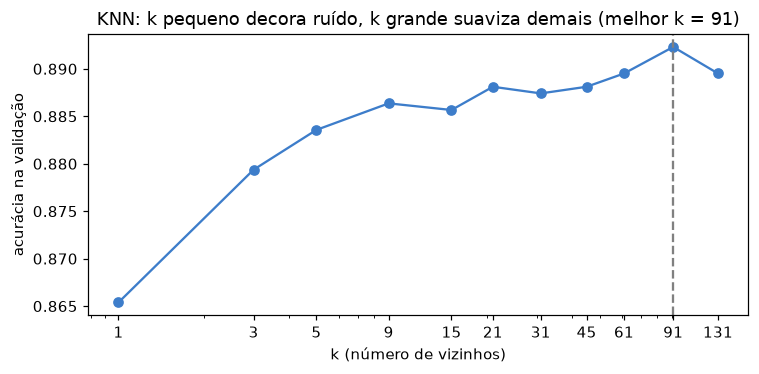

melhor k na validação: 91 → 0.892


In [2]:
ks = [1, 3, 5, 9, 15, 21, 31, 45, 61, 91, 131]
val = []
for k in ks:
    m = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k)).fit(X.loc[ajuste_tr, cols], y[ajuste_tr])
    val.append(accuracy_score(y[ajuste_val], m.predict(X.loc[ajuste_val, cols])))
melhor_k = ks[int(np.argmax(val))]

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(ks, val, marker="o", color="#3d7dca")
ax.axvline(melhor_k, ls="--", c="gray")
ax.set_xscale("log"); ax.set_xticks(ks, ks)
ax.set_xlabel("k (número de vizinhos)"); ax.set_ylabel("acurácia na validação")
ax.set_title(f"KNN: k pequeno decora ruído, k grande suaviza demais (melhor k = {melhor_k})")
plt.tight_layout(); plt.show()
print("melhor k na validação:", melhor_k, "→", round(max(val), 3))

## 2. Comparação no teste (mesmas 15 variáveis)

In [3]:
resultados = {}

def avaliar(nome, modelo):
    t = time.time()
    modelo.fit(X.loc[treino, cols], y[treino])
    t_treino = time.time() - t
    t = time.time()
    pred = modelo.predict(X.loc[teste, cols])
    score = (modelo.decision_function(X.loc[teste, cols]) if hasattr(modelo, "decision_function")
             else modelo.predict_proba(X.loc[teste, cols])[:, 1])
    t_prev = time.time() - t
    resultados[nome] = {"acurácia": accuracy_score(y[teste], pred), "F1": f1_score(y[teste], pred),
                        "ROC-AUC": roc_auc_score(y[teste], score),
                        "treino (s)": t_treino, "previsão de 6.000 (s)": t_prev}

avaliar("Classe majoritária", DummyClassifier(strategy="most_frequent"))
avaliar("Regressão Logística", make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)))
avaliar(f"KNN (k = {melhor_k})", make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=melhor_k)))
avaliar("KNN (k = 1)", make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=1)))
avaliar("SVM RBF (C = 10, γ = 0,05)", make_pipeline(StandardScaler(), SVC(kernel="rbf", C=10, gamma=0.05)))
tabela = pd.DataFrame(resultados).T
tabela.round(3)

,acurácia,F1,ROC-AUC,treino (s),previsão de 6.000 (s)
Classe majoritária,0.510,0.000,0.500,0.010,0.002
Regressão Logística,0.918,0.916,0.976,0.052,0.000
KNN (k = 91),0.911,0.909,0.973,0.066,5.298
KNN (k = 1),0.882,0.879,0.881,0.083,1.584
"SVM RBF (C = 10, γ = 0,05)",0.926,0.925,0.977,9.416,5.599


## 3. Efeito da escala (sem padronização)

In [4]:
escala = {}
for nome, modelo in [(f"KNN (k = {melhor_k})", KNeighborsClassifier(n_neighbors=melhor_k)),
                     ("SVM RBF", SVC(kernel="rbf", C=10, gamma="scale")),
                     ("Regressão Logística", LogisticRegression(max_iter=5000))]:
    sem = modelo.fit(X.loc[treino, cols], y[treino])
    acc_sem = accuracy_score(y[teste], sem.predict(X.loc[teste, cols]))
    com = make_pipeline(StandardScaler(), modelo).fit(X.loc[treino, cols], y[treino])
    acc_com = accuracy_score(y[teste], com.predict(X.loc[teste, cols]))
    escala[nome] = {"com padronização": acc_com, "sem padronização": acc_sem, "queda (pontos)": (acc_com - acc_sem) * 100}
pd.DataFrame(escala).T.round(3)

,com padronização,sem padronização,queda (pontos)
KNN (k = 91),0.911,0.815,9.550
SVM RBF,0.926,0.904,2.150
Regressão Logística,0.918,0.918,-0.033


In [5]:
print("Escala de cada variável (desvio padrão no treino):")
X.loc[treino, cols].std().round(2).sort_values(ascending=False)

Escala de cada variável (desvio padrão no treino):


dif_Sp. Atk     48.86
dif_Attack      46.14
dif_Defense     44.16
dif_Speed       42.34
dif_Sp. Def     40.14
dif_HP          36.69
dif_nocaute      2.23
nocaute_b        1.39
nocaute_a        1.38
log_mult_a       0.62
log_mult_b       0.62
frac_b           0.56
frac_a           0.56
prioridade_a     0.50
prioridade_b     0.50
dtype: float64

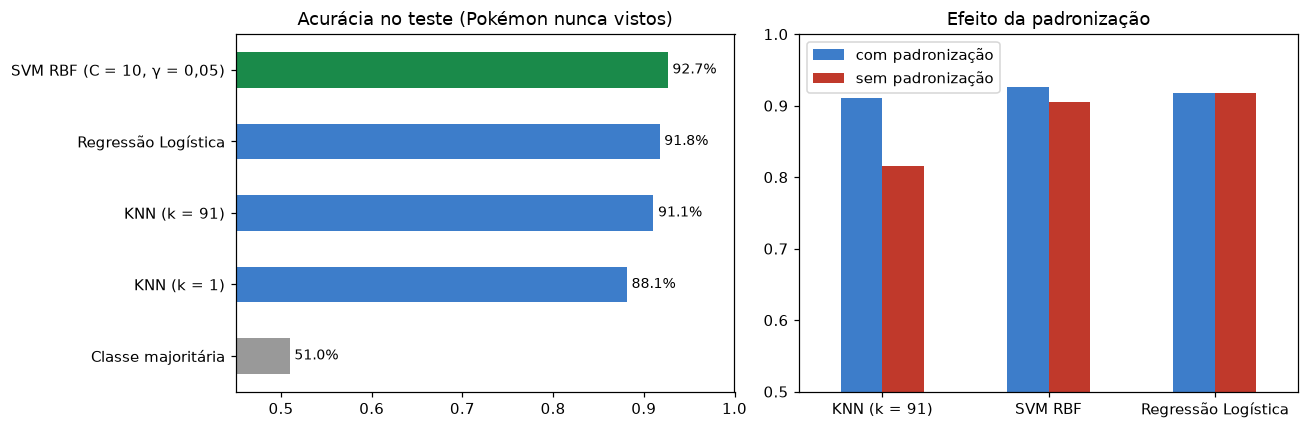

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
ordem = tabela.sort_values("acurácia")
cores = ["#999" if "majoritária" in n else "#1a8a4a" if "SVM" in n else "#3d7dca" for n in ordem.index]
ordem["acurácia"].plot(kind="barh", ax=axes[0], color=cores)
axes[0].set_xlim(.45, 1); axes[0].set_title("Acurácia no teste (Pokémon nunca vistos)")
for i, v in enumerate(ordem["acurácia"]):
    axes[0].text(v + .005, i, f"{v:.1%}", va="center", fontsize=9)
e = pd.DataFrame(escala).T[["com padronização", "sem padronização"]]
e.plot(kind="bar", ax=axes[1], color=["#3d7dca", "#c0392b"], rot=0)
axes[1].set_ylim(.5, 1); axes[1].set_title("Efeito da padronização")
plt.tight_layout(); plt.show()

## 4. Interpretação (E6)

| Modelo (15 variáveis, padronizadas) | Acurácia no teste | ROC-AUC |
|---|---|---|
| **SVM RBF** (C = 10, γ = 0,05) | **92,6%** | **0,977** |
| Regressão Logística | 91,8% | 0,976 |
| KNN (k = 91, escolhido na validação) | 91,1% | 0,973 |
| KNN (k = 1) | 88,2% | 0,881 |

**Hipótese confirmada:** o SVM foi o melhor dos três, mas a diferença é pequena (0,8 ponto sobre a Regressão Logística e
1,5 sobre o KNN). Isso reforça a principal conclusão do projeto: **as variáveis importam mais que o algoritmo**. Com a
informação certa (os golpes), até modelos simples acertam mais de 91%.

**Por que cada um se comporta assim:**
- **KNN** decide pela votação dos k batalhas de treino **mais parecidas**. Com **k = 1**, copia o resultado de uma única
  batalha e "decora o ruído" (inclusive as batalhas decididas pela sorte), o que derruba o ROC-AUC para 0,881. Com
  k grande (91), suaviza e chega perto dos demais. Ele não tem "treino" de verdade, mas precisa comparar cada batalha
  nova com as **30.000** do treino.
- **SVM** também usa semelhança (kernel RBF), mas só com os **5.805 vetores de suporte**, e escolhe a fronteira de
  **margem máxima**: é como um "KNN inteligente", que guarda só as batalhas que importam e pesa cada uma.
- **Regressão Logística** desenha uma fronteira reta. Fica a menos de 1 ponto do SVM, sinal de que o problema é quase
  linear depois das variáveis de golpes.

**Escala (desafio do roteiro):**
| Modelo | Com padronização | Sem padronização | Queda |
|---|---|---|---|
| KNN | 91,1% | 81,5% | **−9,6 pontos** |
| SVM RBF | 92,6% | 90,4% | −2,2 pontos |
| Regressão Logística | 91,8% | 91,8% | nenhuma |

Sem padronizar, as diferenças de atributos (desvio padrão entre 37 e 49) **dominam** o cálculo de distância, e as
variáveis de golpes (desvio entre 0,5 e 2,2), que são as mais informativas, ficam quase invisíveis. O **KNN** depende
só da distância e sofre muito; o **SVM** sofre menos porque o `gamma="scale"` ajusta parte do problema e a margem
ainda aproveita as variáveis maiores; a **Regressão Logística** não usa distância, e os pesos de cada variável
compensam a escala. Conclusão prática: **para KNN e SVM, padronizar é obrigatório.**